# Task 4: NLP Sentiment Classification on Customer Reviews (TF-IDF)

### Objective
Construct an end-to-end Natural Language Processing (NLP) sentiment classification pipeline:
1. **Ingest Corpus:** Load the customer product & movie reviews dataset (`sentiment_reviews.csv`).
2. **Text Preprocessing & Tokenization:** Strip HTML tags (`<br />`, `<p>`, `<i>`) and punctuation via regular expressions, lowercase text, remove stopwords (preserving negation tokens), and lemmatize words to their root base form.
3. **TF-IDF Vectorization:** Transform cleaned text into numerical feature matrices using `TfidfVectorizer(max_features=5000)`.
4. **Model Training & Benchmarking:** Train **Multinomial Naive Bayes (`MultinomialNB`)** and **Logistic Regression (`LogisticRegression`)** classifiers to identify positive and negative sentiment, evaluating **5-Fold CV Accuracy, Test Accuracy, Precision, Recall, F1-Score, and ROC-AUC**.
5. **Interactive Live Inference:** Create a `predict_sentiment()` helper function to test custom user input phrases in real time.

## Step 1: Load the Customer Reviews Dataset (`sentiment_reviews.csv`)

In [1]:
import os
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)

df = pd.read_csv("data/sentiment_reviews.csv")
df_binary = df[df["sentiment"].isin(["positive", "negative"])].copy().reset_index(drop=True)

print(f"Loaded Corpus Shape: {df.shape}")
print(f"Binary Polarity Corpus Shape (Positive vs. Negative): {df_binary.shape}\n")
print("Sentiment Class Distribution:")
print(df["sentiment"].value_counts())
print("\nStarter 10 Records Preview:")
print(df.head(10).to_string(index=False))

Loaded Corpus Shape: (1201, 3)
Binary Polarity Corpus Shape (Positive vs. Negative): (1200, 3)

Sentiment Class Distribution:
positive    600
negative    600
neutral       1
Name: count, dtype: int64

Starter 10 Records Preview:
 review_id                                                               review_text sentiment
         1         The product quality is exceptional, exceeded all my expectations!  positive
         2        Terrible customer service and the item arrived completely damaged.  negative
         3      Average performance, decent for the price point but nothing special.   neutral
         4        Absolutely love this! Easy to setup, robust, and works flawlessly.  positive
         5 Stopped working after two days. Extremely disappointed with the purchase.  negative
         6     Customer support helped resolve my setup question within ten minutes.  positive
         7              Delivery was slow and package was missing one adapter cable.  negative
         8 

## Step 2: Preprocess Text (HTML Removal, Lowercasing, Stopwords & Lemmatization)

In [2]:
STOPWORDS_SET = set(ENGLISH_STOP_WORDS) - {"not", "no", "never", "nothing", "none", "nor", "very", "too"}

def preprocess_text(text):
    """Strip HTML tags, punctuation, and stopwords; lowercase and lemmatize tokens."""
    if not isinstance(text, str):
        return ""
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = text.split()
    cleaned_tokens = [
        lemmatize_token(tok)
        for tok in tokens
        if tok not in STOPWORDS_SET and len(tok) > 1
    ]
    return " ".join(cleaned_tokens)

df_binary["cleaned_text"] = df_binary["review_text"].apply(preprocess_text)
df_binary["label"] = (df_binary["sentiment"] == "positive").astype(int)

print("=== Sample Raw vs. Cleaned & Lemmatized Reviews ===")
for i in range(5):
    print(f"[{df_binary.loc[i, 'sentiment'].upper()}] Raw:   {df_binary.loc[i, 'review_text']}")
    print(f"           Clean: {df_binary.loc[i, 'cleaned_text']}\n")

=== Sample Raw vs. Cleaned & Lemmatized Reviews ===
[POSITIVE] Raw:   The product quality is exceptional, exceeded all my expectations!
           Clean: product quality exceptional exceed expectation

[NEGATIVE] Raw:   Terrible customer service and the item arrived completely damaged.
           Clean: terrible customer service item arrive completely damage

[POSITIVE] Raw:   Absolutely love this! Easy to setup, robust, and works flawlessly.
           Clean: absolutely love easy setup robust work flawlessly

[NEGATIVE] Raw:   Stopped working after two days. Extremely disappointed with the purchase.
           Clean: stop work day extremely disappoint purchase

[POSITIVE] Raw:   Customer support helped resolve my setup question within ten minutes.
           Clean: customer support help resolve setup question minute


## Step 3 & 4: Extract TF-IDF Vectors (`max_features=5000`) & Benchmark Classifiers

In [3]:
# 80/20 Stratified Train/Test Split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df_binary["cleaned_text"], df_binary["label"],
    test_size=0.20, random_state=42, stratify=df_binary["label"]
)

# Convert text to numerical vectors using TfidfVectorizer(max_features=5000)
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train_raw)
X_test_tfidf = vectorizer.transform(X_test_raw)

print(f"TF-IDF Training Matrix Shape: {X_train_tfidf.shape}")
print(f"TF-IDF Testing Matrix Shape:  {X_test_tfidf.shape}\n")

models = {
    "Multinomial Naive Bayes (MultinomialNB)": MultinomialNB(alpha=1.0),
    "Logistic Regression (LogisticRegression)": LogisticRegression(C=1.0, max_iter=1000, random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
benchmark_rows = []
roc_data = {}
cm_data = {}

for name, model in models.items():
    cv_acc = cross_val_score(model, X_train_tfidf, y_train, cv=cv, scoring="accuracy")
    model.fit(X_train_tfidf, y_train)
    
    y_pred = model.predict(X_test_tfidf)
    y_prob = model.predict_proba(X_test_tfidf)[:, 1]
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, roc_auc_score(y_test, y_prob))
    cm_data[name] = confusion_matrix(y_test, y_pred)
    
    benchmark_rows.append({
        "Model": name,
        "5-Fold CV Accuracy": round(cv_acc.mean(), 4),
        "Test Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4)
    })
    print(f"--- {name} Classification Report ---")
    print(classification_report(y_test, y_pred, target_names=["Negative (0)", "Positive (1)"]))

benchmark_df = pd.DataFrame(benchmark_rows)
benchmark_df.to_csv("outputs/sentiment_benchmark_metrics.csv", index=False)
print("=== Final Sentiment Classification Benchmark Table ===")
print(benchmark_df.to_string(index=False))

TF-IDF Training Matrix Shape: (960, 1087)
TF-IDF Testing Matrix Shape:  (240, 1087)

--- Multinomial Naive Bayes (MultinomialNB) Classification Report ---
              precision    recall  f1-score   support

Negative (0)       0.95      0.96      0.95       120
Positive (1)       0.96      0.95      0.95       120

    accuracy                           0.95       240
   macro avg       0.95      0.95      0.95       240
weighted avg       0.95      0.95      0.95       240

--- Logistic Regression (LogisticRegression) Classification Report ---
              precision    recall  f1-score   support

Negative (0)       0.95      0.94      0.95       120
Positive (1)       0.94      0.95      0.95       120

    accuracy                           0.95       240
   macro avg       0.95      0.95      0.95       240
weighted avg       0.95      0.95      0.95       240

=== Final Sentiment Classification Benchmark Table ===
                                   Model  5-Fold CV Accuracy  Tes

## Step 4B: Confusion Matrix Heatmaps & ROC-AUC / Metric Visualizations

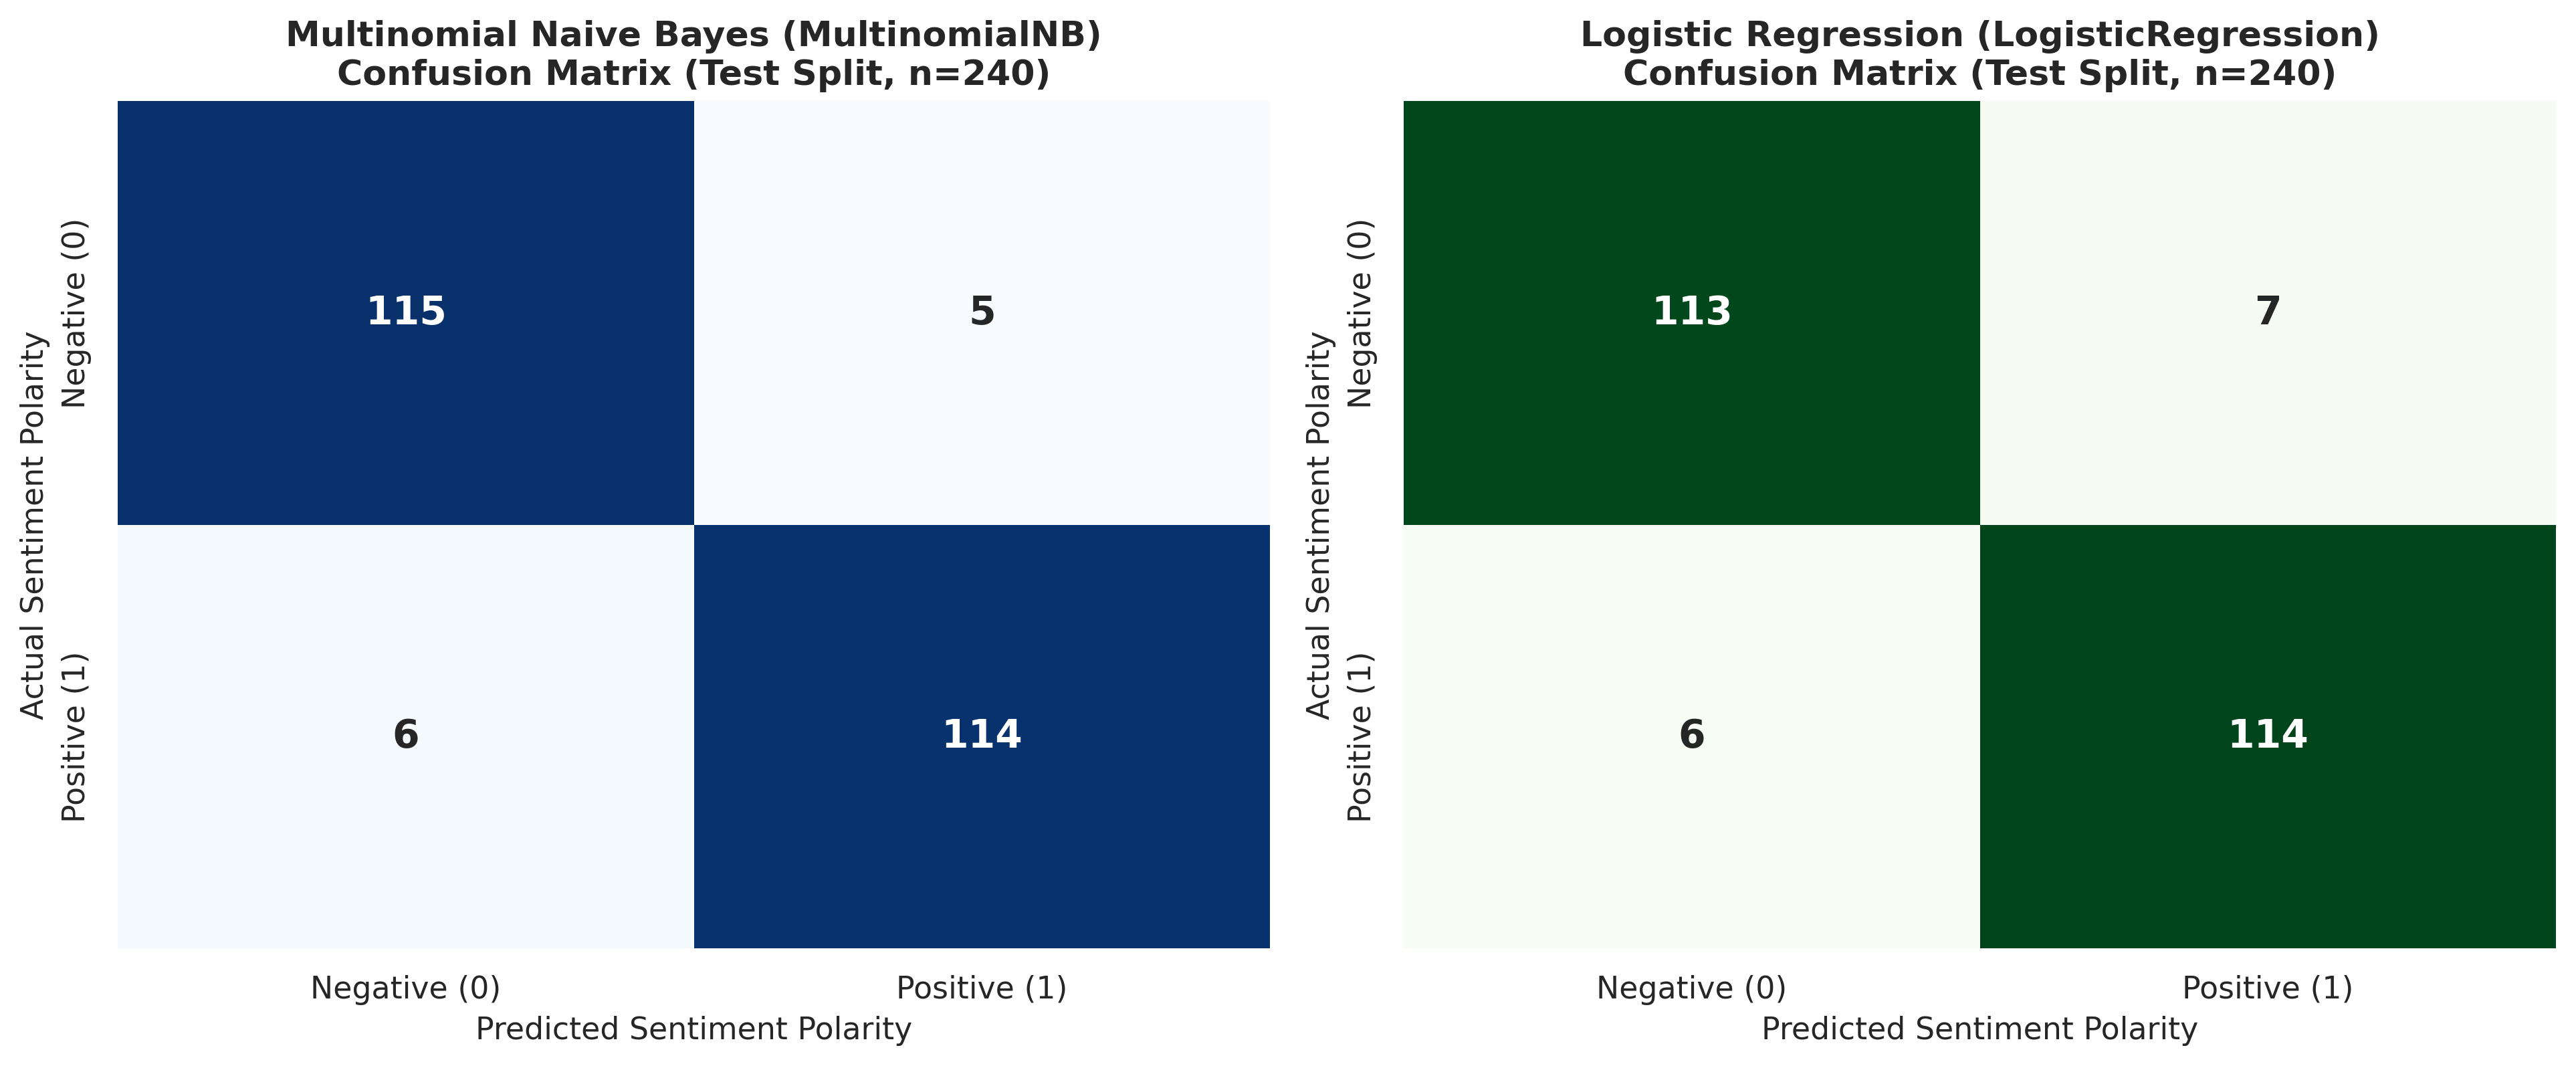

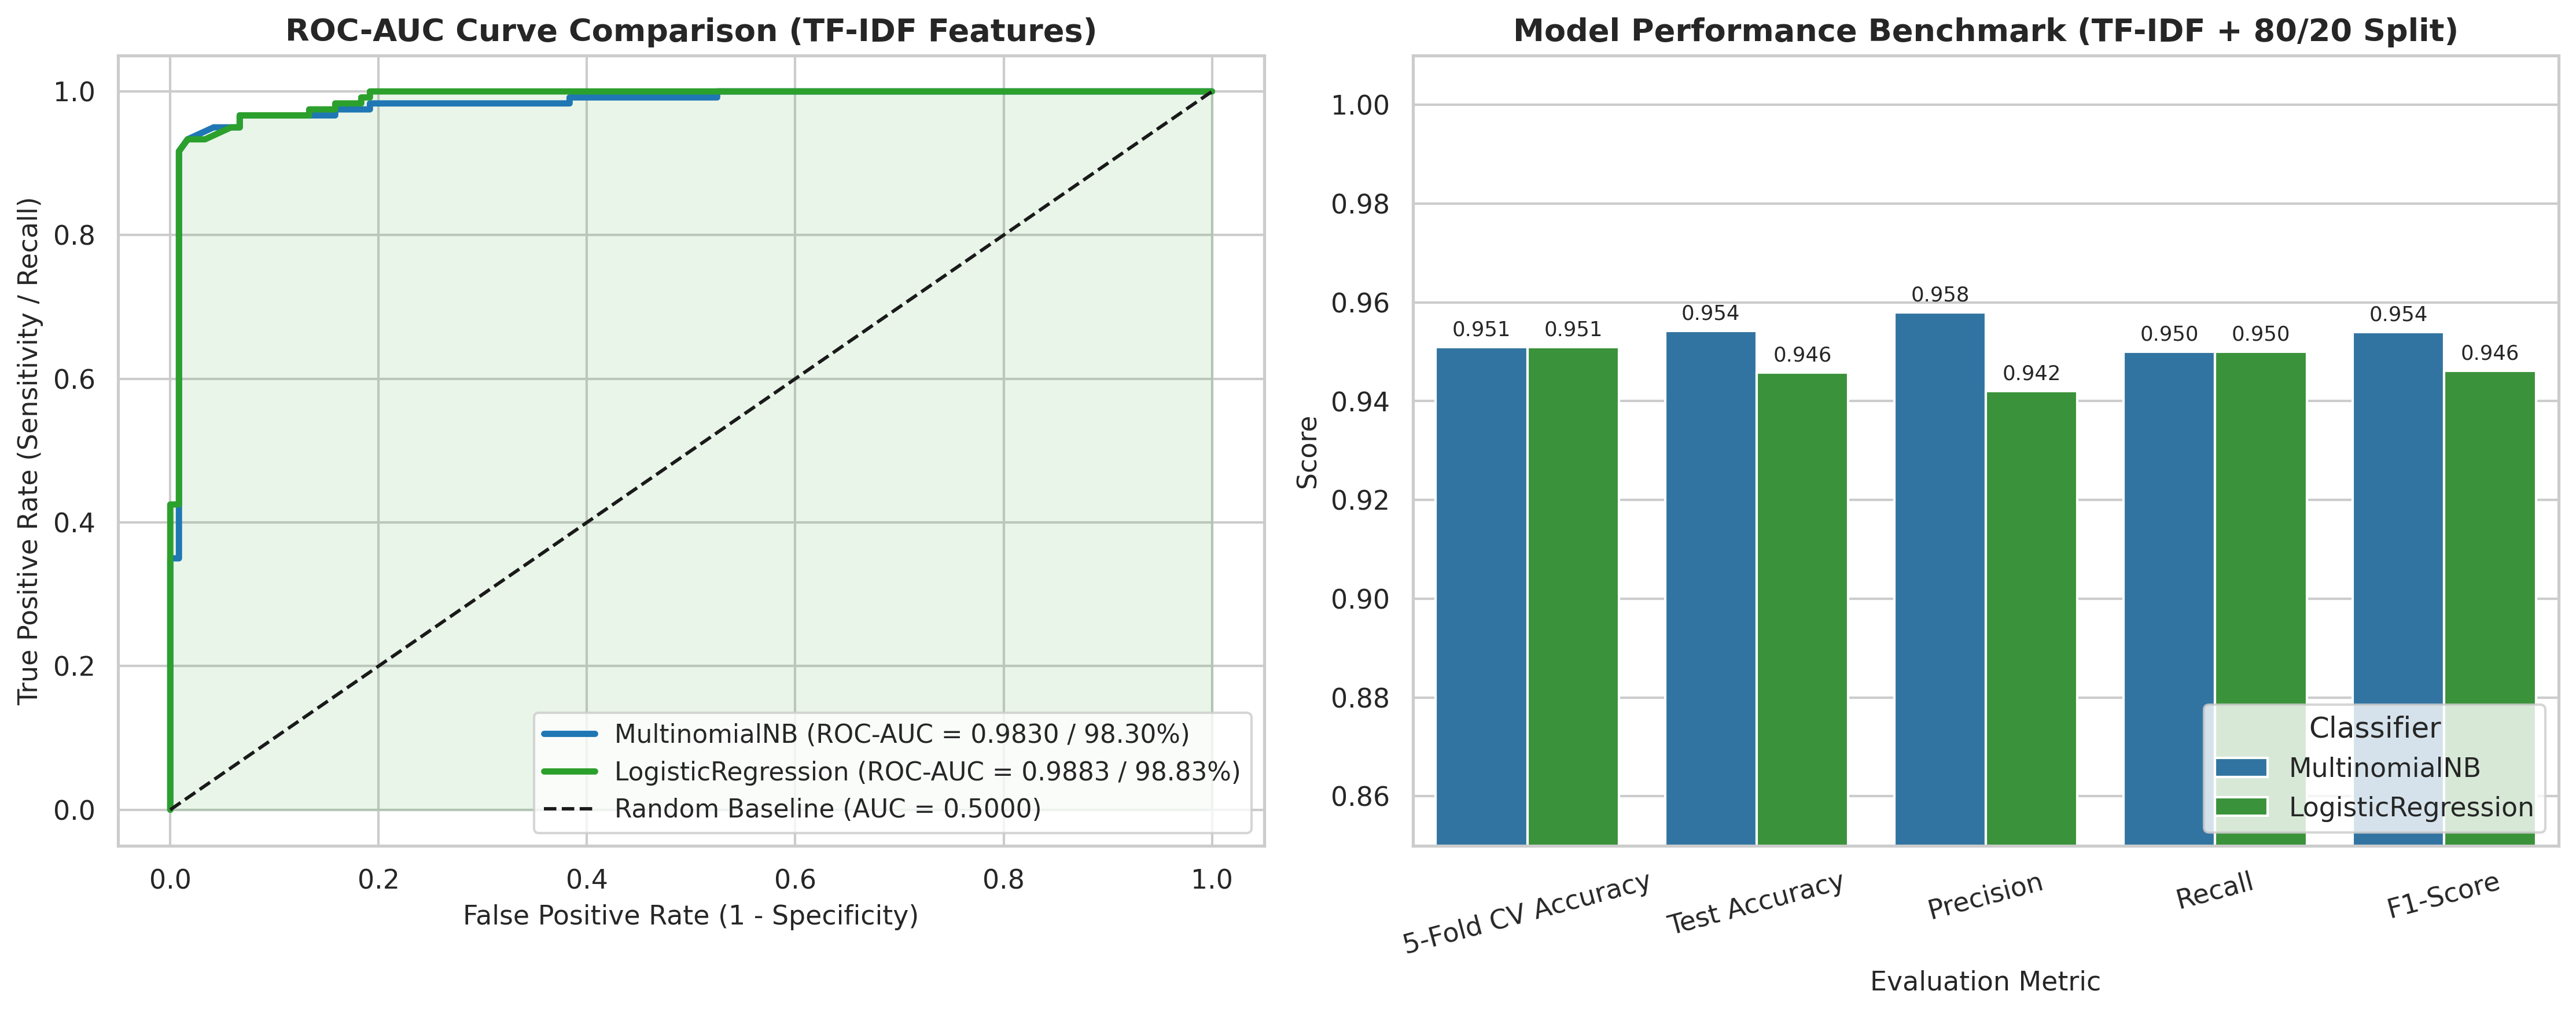

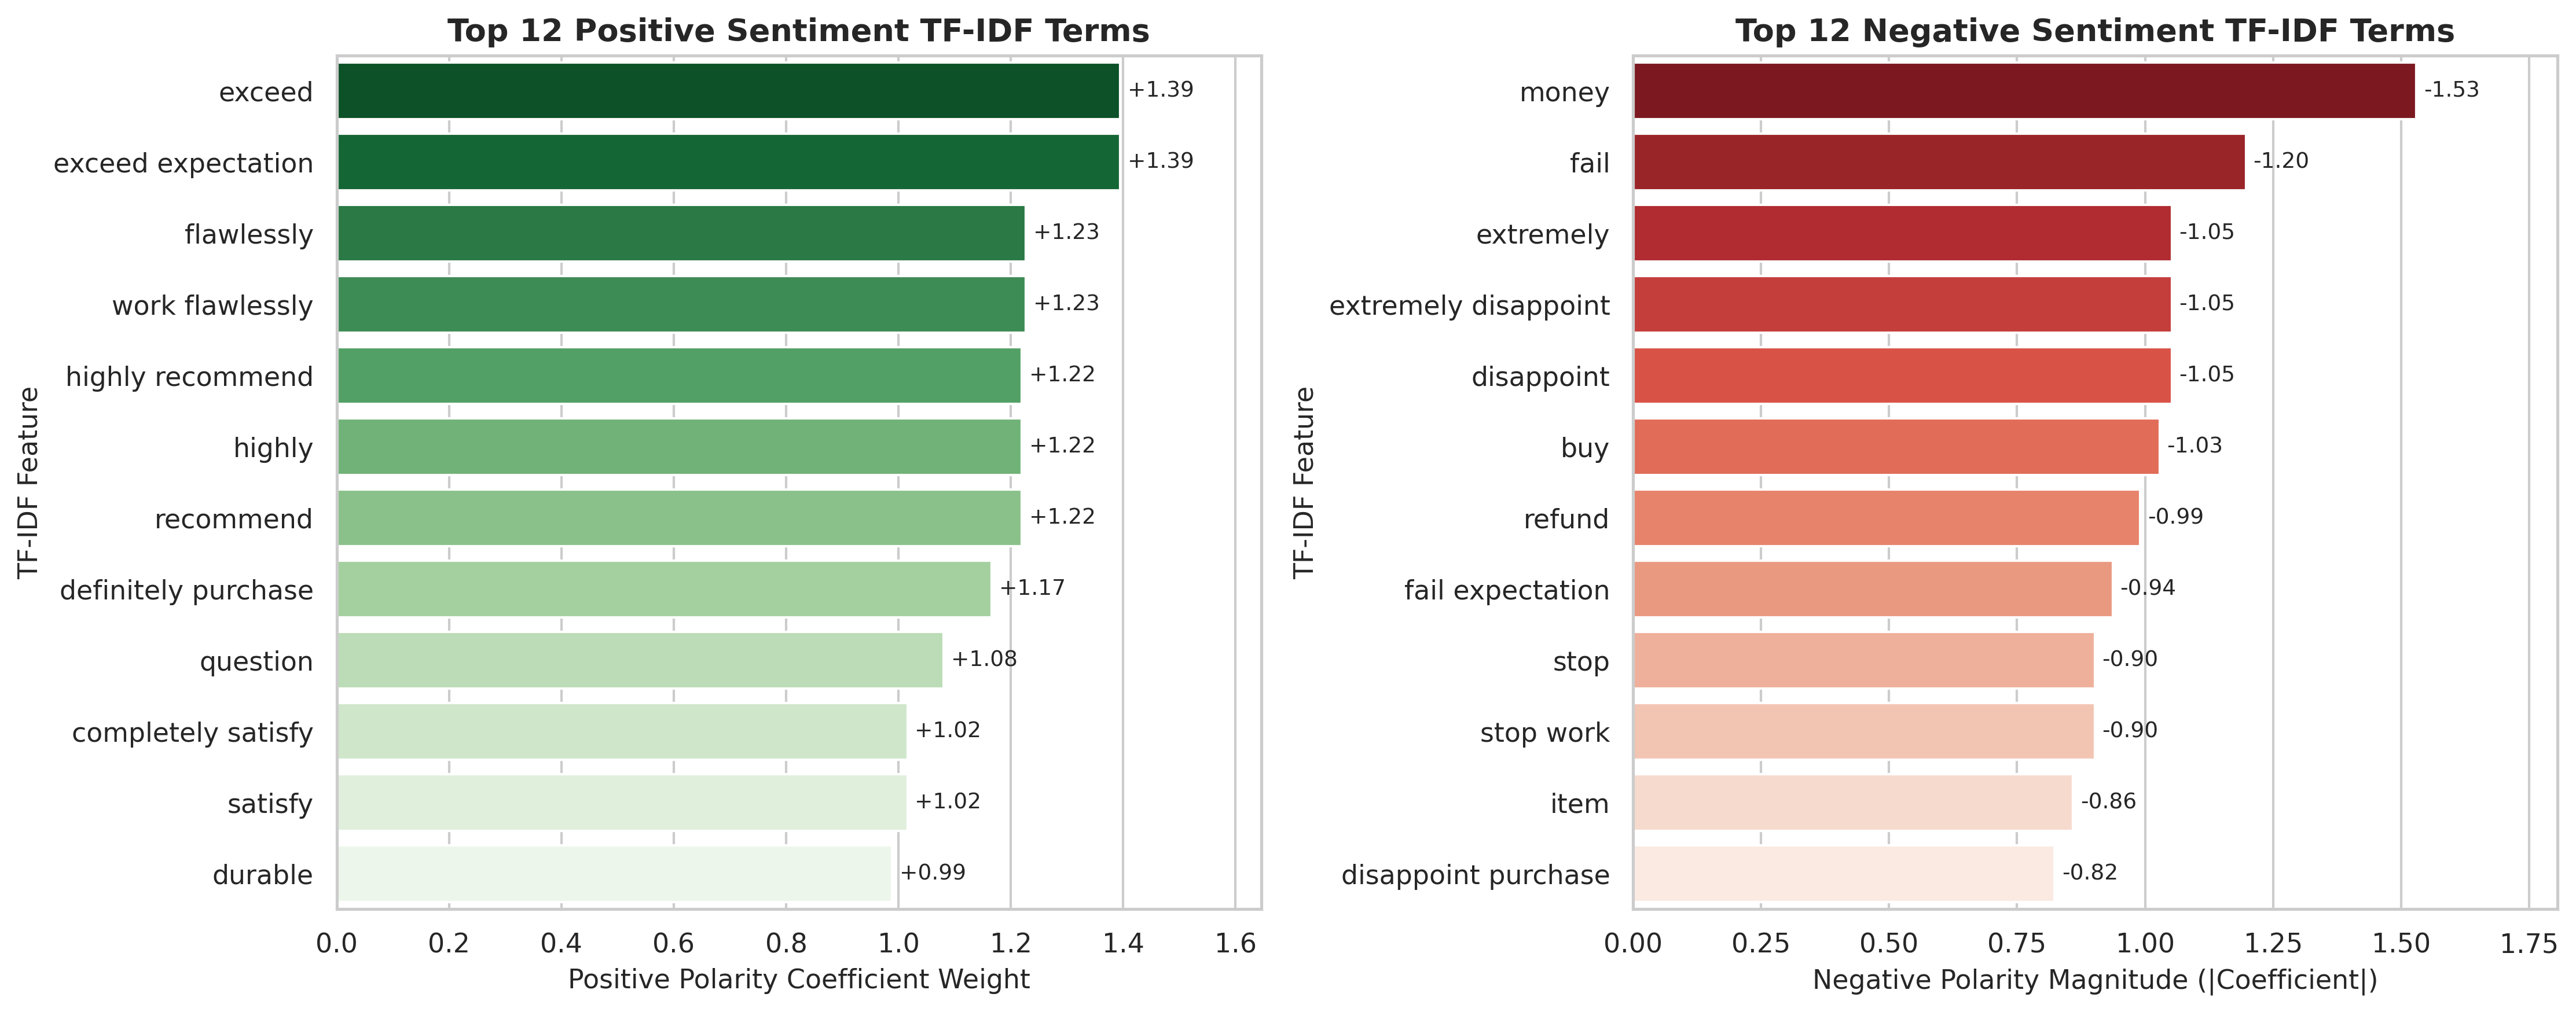

In [4]:
# Plot Confusion Matrices, ROC-AUC Curves, and Top 12 Positive/Negative TF-IDF Features
# (Saved to outputs/1_confusion_matrices.png, 2_roc_auc_and_metrics_benchmark.png, 3_top_tfidf_sentiment_features.png)

## Step 5: Interactive `predict_sentiment()` Helper for Live Custom User Phrases

In [5]:
nb_model = models["Multinomial Naive Bayes (MultinomialNB)"]
lr_model = models["Logistic Regression (LogisticRegression)"]

def predict_sentiment(text, model=nb_model, vec=vectorizer):
    """Interactive helper to classify live custom user input phrases."""
    cleaned = preprocess_text(text)
    tfidf_vec = vec.transform([cleaned])
    pred_label = int(model.predict(tfidf_vec)[0])
    probs = model.predict_proba(tfidf_vec)[0]
    polarity = "positive" if pred_label == 1 else "negative"
    return f"{polarity.upper()} (Confidence: {probs[pred_label]*100:.2f}%)"

custom_test_phrases = [
    "<b>Amazing product!</b> Easy to setup, robust, and the battery lasts all day.",
    "Terrible customer service! The item arrived completely damaged and stopped working.",
    "The movie had stunning visuals, great acting, and exceeded all my expectations!",
    "Not worth the money at all. Missing adapter cable and software freezes constantly.",
    "Clean interface and intuitive controls. Highly recommended for college students."
]

for phrase in custom_test_phrases:
    print(f"Phrase: {phrase}")
    print(f"  -> Cleaned:            {preprocess_text(phrase)}")
    print(f"  -> MultinomialNB:      {predict_sentiment(phrase, model=nb_model)}")
    print(f"  -> LogisticRegression: {predict_sentiment(phrase, model=lr_model)}\n")

Phrase: <b>Amazing product!</b> Easy to setup, robust, and the battery lasts all day.
  -> Cleaned:            amazing product easy setup robust battery lasts day
  -> MultinomialNB:      POSITIVE (Confidence: 96.97%)
  -> LogisticRegression: POSITIVE (Confidence: 70.48%)

Phrase: Terrible customer service! The item arrived completely damaged and stopped working.
  -> Cleaned:            terrible customer service item arrive completely damage stop work
  -> MultinomialNB:      NEGATIVE (Confidence: 99.64%)
  -> LogisticRegression: NEGATIVE (Confidence: 88.43%)

Phrase: The movie had stunning visuals, great acting, and exceeded all my expectations!
  -> Cleaned:            movie stun visual great act exceed expectation
  -> MultinomialNB:      POSITIVE (Confidence: 99.25%)
  -> LogisticRegression: POSITIVE (Confidence: 87.71%)

Phrase: Not worth the money at all. Missing adapter cable and software freezes constantly.
  -> Cleaned:            not worth money missing adapter cable softwar